In [1]:
import sys
sys.path.append("../")  # go up one level from notebooks/ to project root (for using src/)
import os
from dotenv import load_dotenv
import json
import requests
from itertools import combinations, chain
import matplotlib.pyplot as plt
import time
from src.query_builder import build_semantic_scholar_query, load_keywords 
from src.data_collection import collect_semantic_scholar_data, load_config
from src.utils import venn_from_sizes

In [40]:
import importlib
import src.data_collection

# 1. Reload the module itself
importlib.reload(src.data_collection)

# 2. Re-assign the functions to your local variables
collect_semantic_scholar_data = src.data_collection.collect_semantic_scholar_data
load_config = src.data_collection.load_config

In [2]:
# Load API keys from .env file
load_dotenv("../.env")
semantic_scholar_api_key = os.getenv("SEMANTIC_SCHOLAR_API_KEY")

# Semantic Scholar

# Didactic example
Didactic example of how to use the bulk search endpoint. 

In [4]:
# Semantic Scholar didactic example of how to use the bulk search endpoint

# Define the bulk search endpoint
url = "https://api.semanticscholar.org/graph/v1/paper/search/bulk"

# Set up your query parameters
query_params = {
    "query": '"climate change" AND "social media" AND (misinformation OR polarization)',
    # "year": "2020",
    "publicationDateOrYear": "2020-01-01:2020-12-31", 
    "fields": "paperId,title,year"
    # "fields": "paperId,externalIds,title,year,publicationDate,abstract,publicationVenue,journal,citationCount,s2FieldsOfStudy,publicationTypes,authors"
}

# Optional: Add your API key if you have one to avoid rate limits
headers = {"x-api-key": semantic_scholar_api_key}

try:
    response = requests.get(url, params=query_params, headers=headers)
    response.raise_for_status()

    # Parse and print the JSON response
    data = response.json()
    print(json.dumps(data, indent=2))

except requests.exceptions.HTTPError as err:
    print(f"HTTP Error: {err}")
except Exception as e:
    print(f"An error occurred: {e}")

{
  "total": 2,
  "token": null,
  "data": [
    {
      "paperId": "0978a91dbbfdf0b9762fc572e9f7ff3b73b25add",
      "title": "Partisanship, Impeachment, and the Democratic Primaries: American Political Discourse, January - February 2020",
      "year": 2020
    },
    {
      "paperId": "85f4d04076aefafe60a8ead0435b34bf7d8fbfdd",
      "title": "Online misinformation about climate change",
      "year": 2020
    }
  ]
}


## Extract Semantic Scholar data

These are the main papers that we want to analyse. 
They belong to the following subset:
```climate AND nlp AND social_media AND (misinformation OR polarization)```

In [3]:
config = load_config("../config.yml")

ss_config = config["semantic_scholar"]
date_start = config["search"]["date_start"]
date_end = config["search"]["date_end"]

In [8]:
# Build the query

logic = "climate AND nlp AND social_media AND (misinformation OR polarization)"

semantic_scholar_query = build_semantic_scholar_query(
    logic_string=logic,
    keywords_path="../data/search_query/keywords.yml"
)

print(semantic_scholar_query)
print("\nNumber of characters", len(semantic_scholar_query))
print("Semantic Scholar query length limit is 2000 characters") 

("global warming" | "climate change" | "climate science" | "climate denial" | "climate crisis" | "climate skeptic" | "climate skepticism" | "climate skeptics" | "climate skepticist" | "climate action" | "climate misinformation" | "climate disinformation") + ("natural language processing" | NLP | "machine learning" | LLM | AI | "artificial intelligence" | "language model" | "language models" | "neural network" | "neural networks" | GenAI | "Generative AI" | "text mining" | "text processing" | "text classification" | "deep learning" | "transformer*" | "argument mining" | "sentiment analysis") + ("social media" | "social network" | "social networks" | "social platform" | "social platforms" | "online community" | "online communities" | "alternative platform" | "alternative platforms" | alt-tech | Youtube | Rumble | Bitchute | Odysee | Twitch | Quora | Facebook | Instagram | Tiktok | Whatsapp | Telegram | Signal | WeChat | Discord | Threads | Mastodon | Reddit | X | Twitter/x | Twitter | Bl

In [9]:
collect_semantic_scholar_data(
    query=semantic_scholar_query,
    fields=ss_config["fields_full"],
    output_path=f"../data/raw/semantic_scholar/semantic_scholar_data.jsonl",
    date_start=date_start,
    date_end=date_end,
    api_key=semantic_scholar_api_key
)

Function version 5
Query: ("global warming" | "climate change" | "climate science" | "climate denial" | "climate crisis" | "climate skeptic" | "climate skepticism" | "climate skeptics" | "climate skepticist" | "climate action" | "climate misinformation" | "climate disinformation") + ("natural language processing" | NLP | "machine learning" | LLM | AI | "artificial intelligence" | "language model" | "language models" | "neural network" | "neural networks" | GenAI | "Generative AI" | "text mining" | "text processing" | "text classification" | "deep learning" | "transformer*" | "argument mining" | "sentiment analysis") + ("social media" | "social network" | "social networks" | "social platform" | "social platforms" | "online community" | "online communities" | "alternative platform" | "alternative platforms" | alt-tech | Youtube | Rumble | Bitchute | Odysee | Twitch | Quora | Facebook | Instagram | Tiktok | Whatsapp | Telegram | Signal | WeChat | Discord | Threads | Mastodon | Reddit | X 

(88, 88)

## Examine the interseccions

In [6]:
sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]
all_combinations = list(chain.from_iterable(combinations(sets, r) for r in range(1, len(sets) + 1)))

# Dictionary to store the results
intersections_totals = {}

for combination in all_combinations:

    # Logic
    logic = " AND ".join(combination)
    print(f"Retrieving data for: {logic}")

    #Name for the file
    file_name = "_".join(logic.split(" "))
    
    # Build the query
    semantic_scholar_query = build_semantic_scholar_query(
        logic_string=logic,
        keywords_path="../data/search_query/keywords.yml"
    )

    # Extract data
    total_downloaded, grand_total = collect_semantic_scholar_data(
        query=semantic_scholar_query,
        fields=ss_config["fields_lite"],
        output_path=f"../data/raw/semantic_scholar/sets/{file_name}.jsonl", 
        date_start=date_start,
        date_end=date_end,
        api_key=semantic_scholar_api_key
    )

    # Store the total number of results for this combination
    intersections_totals[logic] = {"total_downloaded": total_downloaded, "grand_total": grand_total, "complete": total_downloaded == grand_total}

    sleep_time = 1.1 if semantic_scholar_api_key else 3.5
    time.sleep(sleep_time)  # Sleep to respect rate limits

# Save the totals to a JSON file
with open("../data/raw/semantic_scholar/sets/intersections_totals.json", "w") as f:
    json.dump(intersections_totals, f, indent=2)

Retrieving data for: climate
Query: ("global warming" | "climate change" | "climate science" | "climate denial" | "climate crisis" | "climate skeptic" | "climate skepticism" | "climate skeptics" | "climate skepticist" | "climate action" | "climate misinformation" | "climate disinformation")
Output: ../data/raw/semantic_scholar/sets/climate.jsonl
API key: yes | Sleep: 1.1s
Fetching batch | total so far: 0
Total papers to retrieve: 350270
Fetching batch | total so far: 1000
Fetching batch | total so far: 2000
Fetching batch | total so far: 3000
Fetching batch | total so far: 4000
Fetching batch | total so far: 5000
Fetching batch | total so far: 6000
Fetching batch | total so far: 7000
Fetching batch | total so far: 8000
Fetching batch | total so far: 9000
Fetching batch | total so far: 10000
Fetching batch | total so far: 11000
Fetching batch | total so far: 12000
Fetching batch | total so far: 13000
Fetching batch | total so far: 14000
Fetching batch | total so far: 15000
Fetching batc

In [ ]:
# See the incomplete downloads
for logic in intersections_totals:
    if not(intersections_totals[logic]["complete"]):
        print(logic, intersections_totals[logic])

# In some cases the mismatch between total_downloaded and grand_total is minimal (e.g., 99 downloaded vs 100 total), which suggests that the download process was mostly successful. In this cases the API does not return any error.

climate {'total_downloaded': 349811, 'grand_total': 350270, 'complete': False}
nlp {'total_downloaded': 2414532, 'grand_total': 2414555, 'complete': False}
social_media {'total_downloaded': 4082864, 'grand_total': 4083218, 'complete': False}
polarization {'total_downloaded': 193200, 'grand_total': 193201, 'complete': False}
nlp AND social_media {'total_downloaded': 310922, 'grand_total': 310927, 'complete': False}
nlp AND polarization {'total_downloaded': 6661, 'grand_total': 6662, 'complete': False}


In [49]:
#Load the totals from the JSON file
with open("../data/raw/semantic_scholar/sets/intersections_totals.json", "r") as f:
    intersections_totals = json.load(f)

In [41]:
def venn_from_topics(topics, colors, sizes):
    """
    Draw a 3-set Venn diagram for a given triple of topic names.

    Parameters
    ----------
    topics : tuple of 3 strings
        The three set names, e.g. ("climate", "nlp", "misinformation").
    colors : dict
        Maps topic name -> matplotlib color string.
        for instance, {"climate": "green", "nlp": "orange", "misinformation": "red"}.
    sizes : dict
        Maps topic name or "X AND Y" / "X AND Y AND Z" -> integer count.
        Keys use " AND " as separator; order within a key does not matter.
        For instance, {"climate": 100, "nlp": 80, "misinformation": 50, "climate AND nlp": 30, ...}.

    Returns
    -------
    diagram, ax
    """
    if len(topics) != 3:
        raise ValueError("topics must contain exactly 3 names.")

    a_name, b_name, c_name = topics

    def get_size(key_topics):
        """Look up a single or multi-topic size, trying all orderings."""
        if len(key_topics) == 1:
            return sizes[key_topics[0]]
        # Build all permutations of the AND-joined key
        from itertools import permutations
        for perm in permutations(key_topics):
            key = " AND ".join(perm)
            if key in sizes:
                return sizes[key]
        raise KeyError(
            f"Could not find size for topics {key_topics} in any order. "
            f"Tried keys like '{' AND '.join(key_topics)}'."
        )

    a   = get_size([a_name])
    b   = get_size([b_name])
    c   = get_size([c_name])
    ab  = get_size([a_name, b_name])
    ac  = get_size([a_name, c_name])
    bc  = get_size([b_name, c_name])
    abc = get_size([a_name, b_name, c_name])

    set_colors = (
        colors.get(a_name, "blue"),
        colors.get(b_name, "blue"),
        colors.get(c_name, "blue"),
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    diagram, ax = venn_from_sizes(
        a=a, b=b, c=c,
        ab=ab, ac=ac, bc=bc, abc=abc,
        set_labels=topics,
        ax=ax,
        set_colors=set_colors,
        alpha=0.6,
    )
    ax.set_title(" ∩ ".join(topics), fontsize=13, pad=12)
    plt.tight_layout()
    return diagram, ax

ValueError: Logically inconsistent inputs — the following exclusive region counts came out negative:
  {'abC (only C)': -71647}
Verify that abc ≤ ab, ac, bc and that each pairwise intersection is ≤ the smaller of its two parent sets.

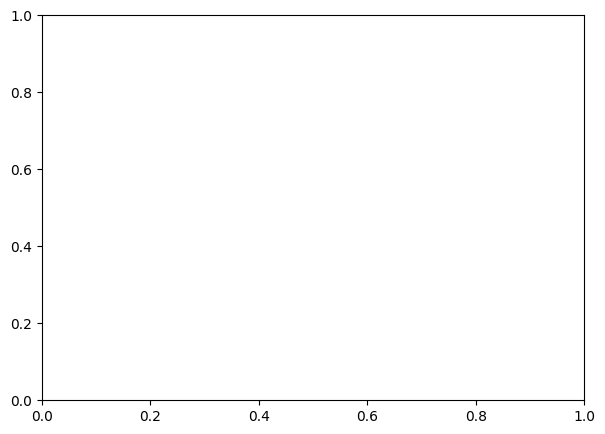

In [ ]:
# from src.utils import venn_from_topics

all_combinations_of_3_sets = [i for i in all_combinations if len(i)==3]

# Colors for each set
colors = {
    "climate": "green",
    "nlp": "blue",
    "social_media": "yellow",
    "misinformation": "red",
    "polarization": "gray"
}

for sets in all_combinations_of_3_sets:
    venn_from_topics(
        topics=sets,
        colors=colors,
        sizes=intersections_totals
    )

In [ ]:
venn_from_topics(
    topics=("climate", "nlp", "social_media"),
    colors=colors,
    sizes=intersections_totals
)

In [47]:
print(intersections_totals["climate"])
print(intersections_totals["nlp"]) 
print(intersections_totals["social_media"]) 
print(intersections_totals["climate AND nlp"]) 
print(intersections_totals["climate AND social_media"]) 
print(intersections_totals["nlp AND social_media"]) 
print(intersections_totals["climate AND nlp AND social_media"])

350077
487995
259998
19024
22358
310748
1461


In [ ]:
# Horizontal bar chart of the totals for each topic and their intersections
plt.figure(figsize=(10, 6))
plts = plt.barh(list(intersections_totals.keys()), list(intersections_totals.values()), color="skyblue")
plt.xlabel("Number of Papers")
plt.ylabel("Topics")
plt.show()
